# Site figures

The charts on the project page, drawn from the aggregate result files in `results/verified/`. Presentation only.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUT = ROOT / "figures" / "site"
OUT.mkdir(parents=True, exist_ok=True)

BLUE, RED, GREY, LIGHT = "#2166ac", "#b2182b", "#8c8c8c", "#d9d9d9"
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Inter", "Helvetica", "Arial", "DejaVu Sans"],
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#444444",
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#eeeeee",
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "figure.dpi": 100,
    "savefig.dpi": 200,
    "savefig.bbox": "tight",
})


def titled(ax, title, sub=None):
    ax.set_title(title, pad=24 if sub else 10)
    if sub:
        ax.text(0, 1.02, sub, transform=ax.transAxes, fontsize=10, color="#555555", va="bottom")


def save(fig, name):
    fig.savefig(OUT / name, facecolor="white")
    plt.show()


## Where the edge goes

Decile long-short on the broad composite, 2003 to 2026, spreads charged on the names traded each month.

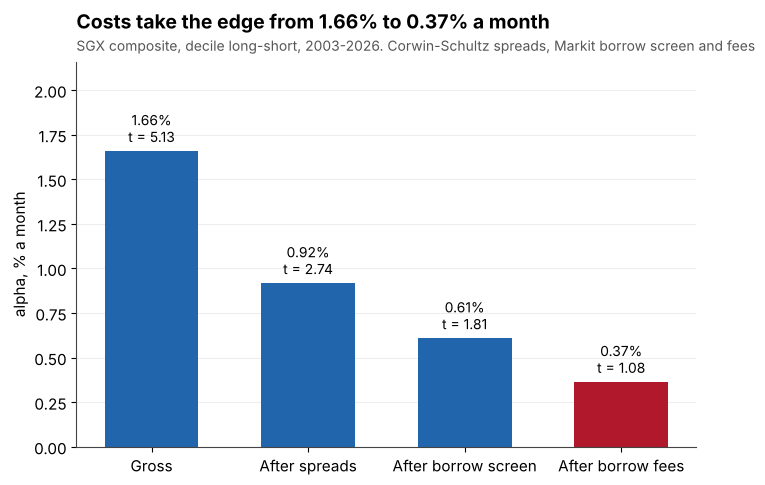

In [2]:
wf = pd.read_csv(ROOT / "results/verified/waterfall_schemes_traded_days.csv")
ls = wf[(wf.Score == "Composite") & (wf.Book == "Long-short")]
gross = ls[ls.Stage.str.startswith("1.")].iloc[0]
traded = ls[ls.Costing == "Traded"]
rows = [("Gross", gross["Alpha%mo"], gross.t)] + [
    (lab, r["Alpha%mo"], r.t) for lab, (_, r) in zip(["After spreads", "After borrow screen", "After borrow fees"], traded.iterrows())
]
fig, ax = plt.subplots(figsize=(8, 5))
labels = [r[0] for r in rows]
vals = [r[1] for r in rows]
cols = [BLUE, BLUE, BLUE, RED]
bars = ax.bar(labels, vals, color=cols, width=0.6)
for b, (_, v, t) in zip(bars, rows):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.03, f"{v:.2f}%\nt = {t:.2f}", ha="center", va="bottom", fontsize=10)
ax.set_ylabel("alpha, % a month")
ax.set_ylim(0, max(vals) * 1.3)
ax.grid(axis="x", visible=False)
titled(ax, "Costs take the edge from 1.66% to 0.37% a month",
       "SGX composite, decile long-short, 2003-2026. Corwin-Schultz spreads, Markit borrow screen and fees")
save(fig, "cost_waterfall.png")

## STI-core book against the equal-weight benchmark

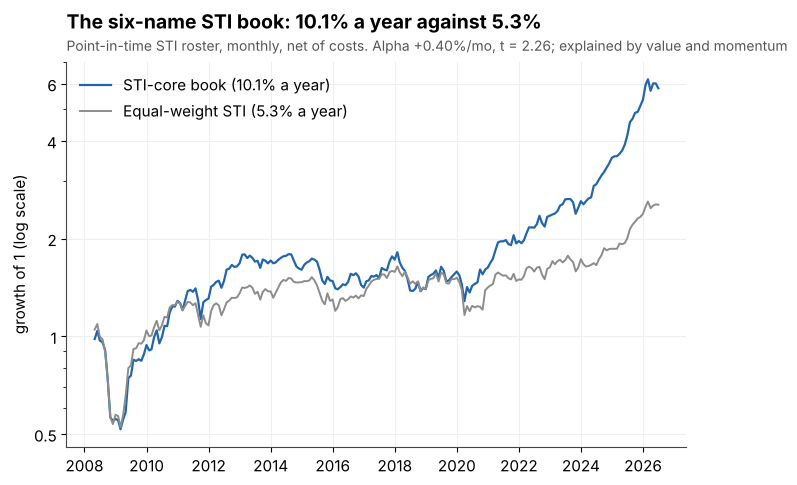

In [3]:
r = pd.read_csv(ROOT / "results/verified/sti_core_returns.csv", parse_dates=["Date"]).set_index("Date")
g = (1 + r[["net", "bm"]]).cumprod()
yrs = len(r) / 12
cagr = g.iloc[-1] ** (1 / yrs) - 1
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(g.index, g.net, color=BLUE, lw=1.6, label=f"STI-core book ({cagr.net:.1%} a year)")
ax.plot(g.index, g.bm, color=GREY, lw=1.4, label=f"Equal-weight STI ({cagr.bm:.1%} a year)")
ax.set_yscale("log")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))
ax.yaxis.set_minor_formatter(plt.NullFormatter())
ax.set_yticks([0.5, 1, 2, 4, 6])
ax.set_ylabel("growth of 1 (log scale)")
ax.legend(frameon=False, loc="upper left")
titled(ax, "The six-name STI book: 10.1% a year against 5.3%",
       "Point-in-time STI roster, monthly, net of costs. Alpha +0.40%/mo, t = 2.26; explained by value and momentum")
save(fig, "sti_core.png")